# Phase 2 — Spread, z-score signal and in-sample validation

Pair **INTC (A) / AMD (B)**. **In-sample only: dates < 2013-01-01.** The out-of-sample period is not loaded.

The whole design below was **pre-registered in `EXPERIMENTS.md` (2026-10-10 11:56 CEST) before any computation** and is not modified after seeing results:

- OLS on log adjusted prices, IS only: `log P_INTC = α + β·log P_AMD + ε`; spread `s = log P_INTC − β·log P_AMD`.
- z-score with a rolling window of L days ending at day t (past data only).
- Long spread if z < −e, short spread if z > +e, exit when z crosses 0, direct flip allowed, no stop-loss.
- Signal at the close of day t, position from day t+1 (`shift(1)`).
- Daily P&L on gross capital `position × (r_INTC − β·r_AMD)/(1+|β|)`; costs 5 bp per leg per position change; rf = 0.
- Grid e ∈ {1.5, 2.0, 2.5} × L ∈ {20, 60, 120}; **main configuration fixed a priori: e = 2.0, L = 60**. Plus one robustness run: main configuration with `shift(2)`. 10 backtests in total.

Why log prices instead of the price levels used in the brief: over 1980–2012 prices span about two orders of magnitude (Phase 1), so a dollar spread is not comparable across decades; a unit of log spread is the same *percentage* mispricing in 1985 and in 2010.

In [1]:
import logging

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display
from plotly.subplots import make_subplots

from pairs.backtest import run_strategy
from pairs.config import SPLIT_DATE, TICKER_A, TICKER_B
from pairs.data import load_pair
from pairs.metrics import performance_summary
from pairs.plotting import DERIVED_COLOR, apply_style, save_figure
from pairs.signal import rolling_zscore
from pairs.spread import BETA_WARNING_THRESHOLD, compute_spread, fit_hedge_ratio, stationarity_tests

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("kaleido", "choreographer"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

# Pre-registered design (EXPERIMENTS.md, 2026-10-10 11:56 CEST). Do not edit.
ENTRIES = [1.5, 2.0, 2.5]
LOOKBACKS = [20, 60, 120]
MAIN_ENTRY, MAIN_LOOKBACK = 2.0, 60
COST_BPS = 5.0

In [2]:
prices = load_pair(end=SPLIT_DATE)
assert prices.index.max() < pd.Timestamp(SPLIT_DATE), "out-of-sample date leaked"
assert len(prices) == 8273

INFO pairs.data: Loaded INTC/AMD: 8273 common days, 1980-03-17 -> 2012-12-31 (end=2013-01-01, exclusive)


## 1. Hedge regression (IS)

- **β (hedge ratio)**: on average a 1% move in AMD goes with a β% move in INTC. It sets how much AMD to short per unit of INTC (in capital terms, because the regression is in logs).
- **α**: the intercept, a constant level shift of log INTC. It does not affect the trading signal, because the rolling z-score removes any constant.
- **R²**: share of the variance of log INTC explained by log AMD. R² does not measure whether the pair is cointegrated: it can be high for unrelated series that trend together (KO/PEP appendix: R² = 0.975 but Engle–Granger p = 0.45) and low when the trends diverge, as here (R² = 0.15). The stationarity tests below are what matters.

In [3]:
fit = fit_hedge_ratio(prices, end=SPLIT_DATE)
if fit.beta <= 0:
    print(f"PROBLEM: beta = {fit.beta:.4f} <= 0, the AMD leg is not a hedge.")
elif fit.beta <= BETA_WARNING_THRESHOLD:
    print(f"PROBLEM: beta = {fit.beta:.4f} is close to zero, the AMD leg barely hedges INTC.")
else:
    print(f"beta = {fit.beta:.4f} > {BETA_WARNING_THRESHOLD}: AMD acts as a hedge for INTC.")

pd.DataFrame(
    {
        "value": [fit.alpha, fit.beta, fit.r_squared, fit.n_obs, fit.first_date, fit.last_date],
    },
    index=["alpha", "beta", "R²", "n_obs", "first date", "last date"],
)

INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 1980-03-17..2012-12-31: alpha=-1.2311 beta=1.0471 R2=0.1499


beta = 1.0471 > 0.1: AMD acts as a hedge for INTC.


,value
alpha,-1.231062
beta,1.047123
R²,0.149872
n_obs,8273
first date,1980-03-17
last date,2012-12-31


## 2. Is the IS spread stationary?

Both tests have the null hypothesis "unit root", i.e. the spread does **not** revert to a mean. A small p-value (e.g. < 0.05) is evidence *for* mean reversion.

- **ADF on the spread**: reported, but optimistic, because OLS chose β to make the spread look as stationary as possible.
- **Engle–Granger**: same idea with critical values that account for β being estimated. This is the test to rely on.

Below the table, as descriptive numbers only (pre-registered not to change the grid): the AR(1) coefficient b of `Δs_t = a + b·s_{t−1} + u_t` and the implied half-life `−ln 2 / ln(1+b)`, i.e. how long a deviation takes on average to halve.

In [4]:
st = stationarity_tests(prices, beta=fit.beta, end=SPLIT_DATE)
display(
    pd.DataFrame(
        {"statistic": [st.adf_stat, st.eg_stat], "p_value": [st.adf_pvalue, st.eg_pvalue]},
        index=[f"ADF on spread (lags={st.adf_lags})", "Engle–Granger"],
    ).round(4)
)
print(
    f"Descriptive only: AR(1) coefficient b = {st.ar1_coef:.5f}, implied half-life ≈ "
    f"{st.half_life_days:,.0f} trading days (≈ {st.half_life_days / 252:.0f} years). "
    "The correct significance test for b is the ADF above: under the unit-root null the "
    "usual t-test on b is not valid."
)

,statistic,p_value
ADF on spread (lags=5),-0.3132,0.9236
Engle–Granger,-0.3147,0.9752


Descriptive only: AR(1) coefficient b = -0.00010, implied half-life ≈ 6,705 trading days (≈ 27 years). The correct significance test for b is the ADF above: under the unit-root null the usual t-test on b is not valid.


## 3. The IS spread and its mean

INFO pairs.plotting: Saved figure 02a_spread_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


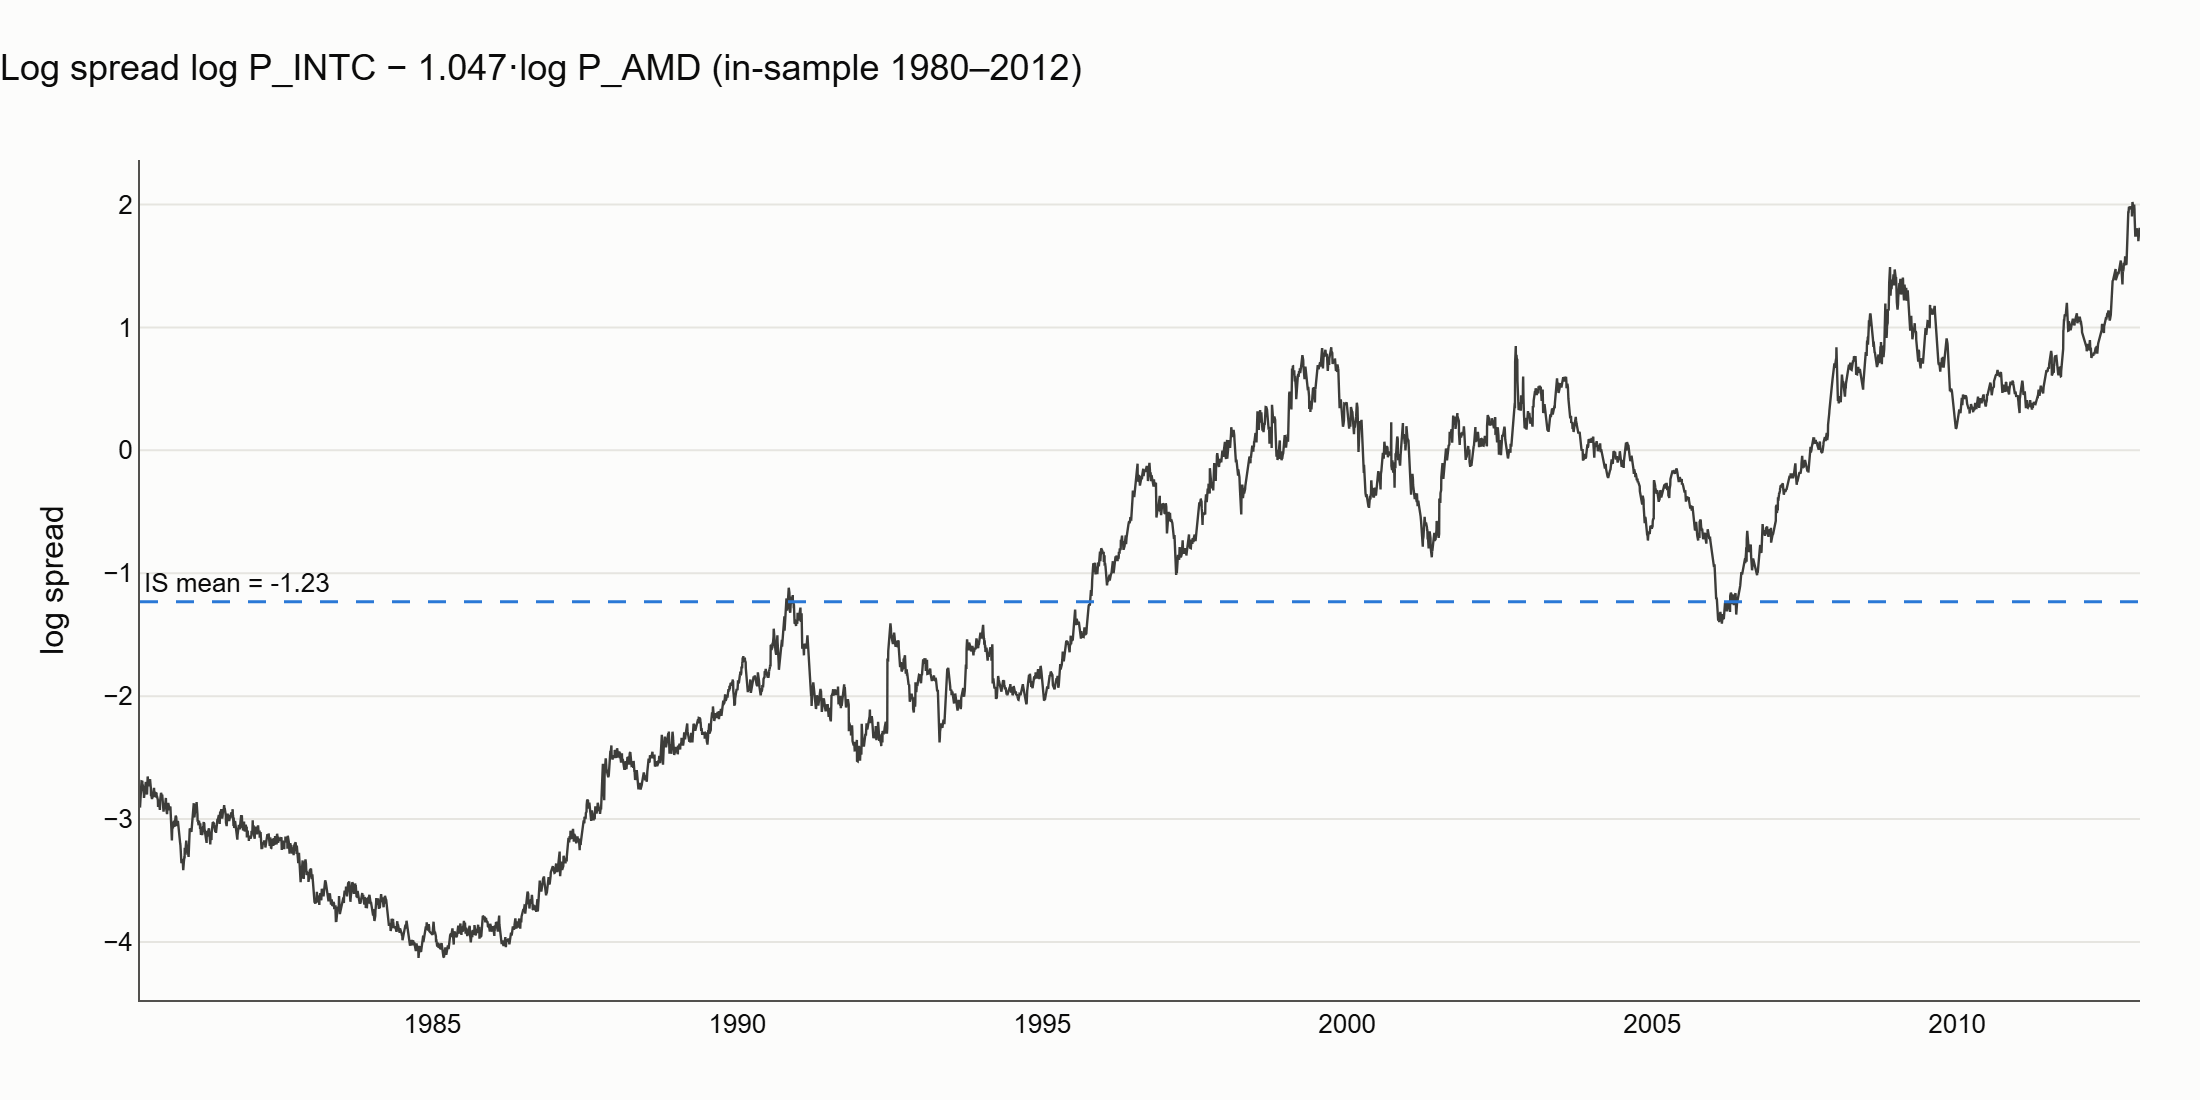

In [5]:
spread = compute_spread(prices, fit.beta)
# OLS residuals have mean zero, so the mean of the spread (which excludes alpha) equals alpha.
assert abs(spread.mean() - fit.alpha) < 1e-8

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=spread.index, y=spread, name="spread", line={"color": DERIVED_COLOR, "width": 1.2})
)
fig.add_hline(
    y=spread.mean(),
    line={"color": "#2a78d6", "width": 1.5, "dash": "dash"},
    annotation_text=f"IS mean = {spread.mean():.2f}",
    annotation_position="top left",
)
apply_style(fig, f"Log spread log P_INTC − {fit.beta:.3f}·log P_AMD (in-sample 1980–2012)")
fig.update_layout(showlegend=False)
fig.update_yaxes(title_text="log spread")
_, png = save_figure(fig, "02a_spread_is")
display(Image(filename=png))

## 4. z-score of the main configuration (L = 60) with the ±2 thresholds

Below −2: long spread (long INTC, short β AMD). Above +2: short spread. Exit when z crosses 0.

INFO pairs.plotting: Saved figure 02b_zscore_main_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


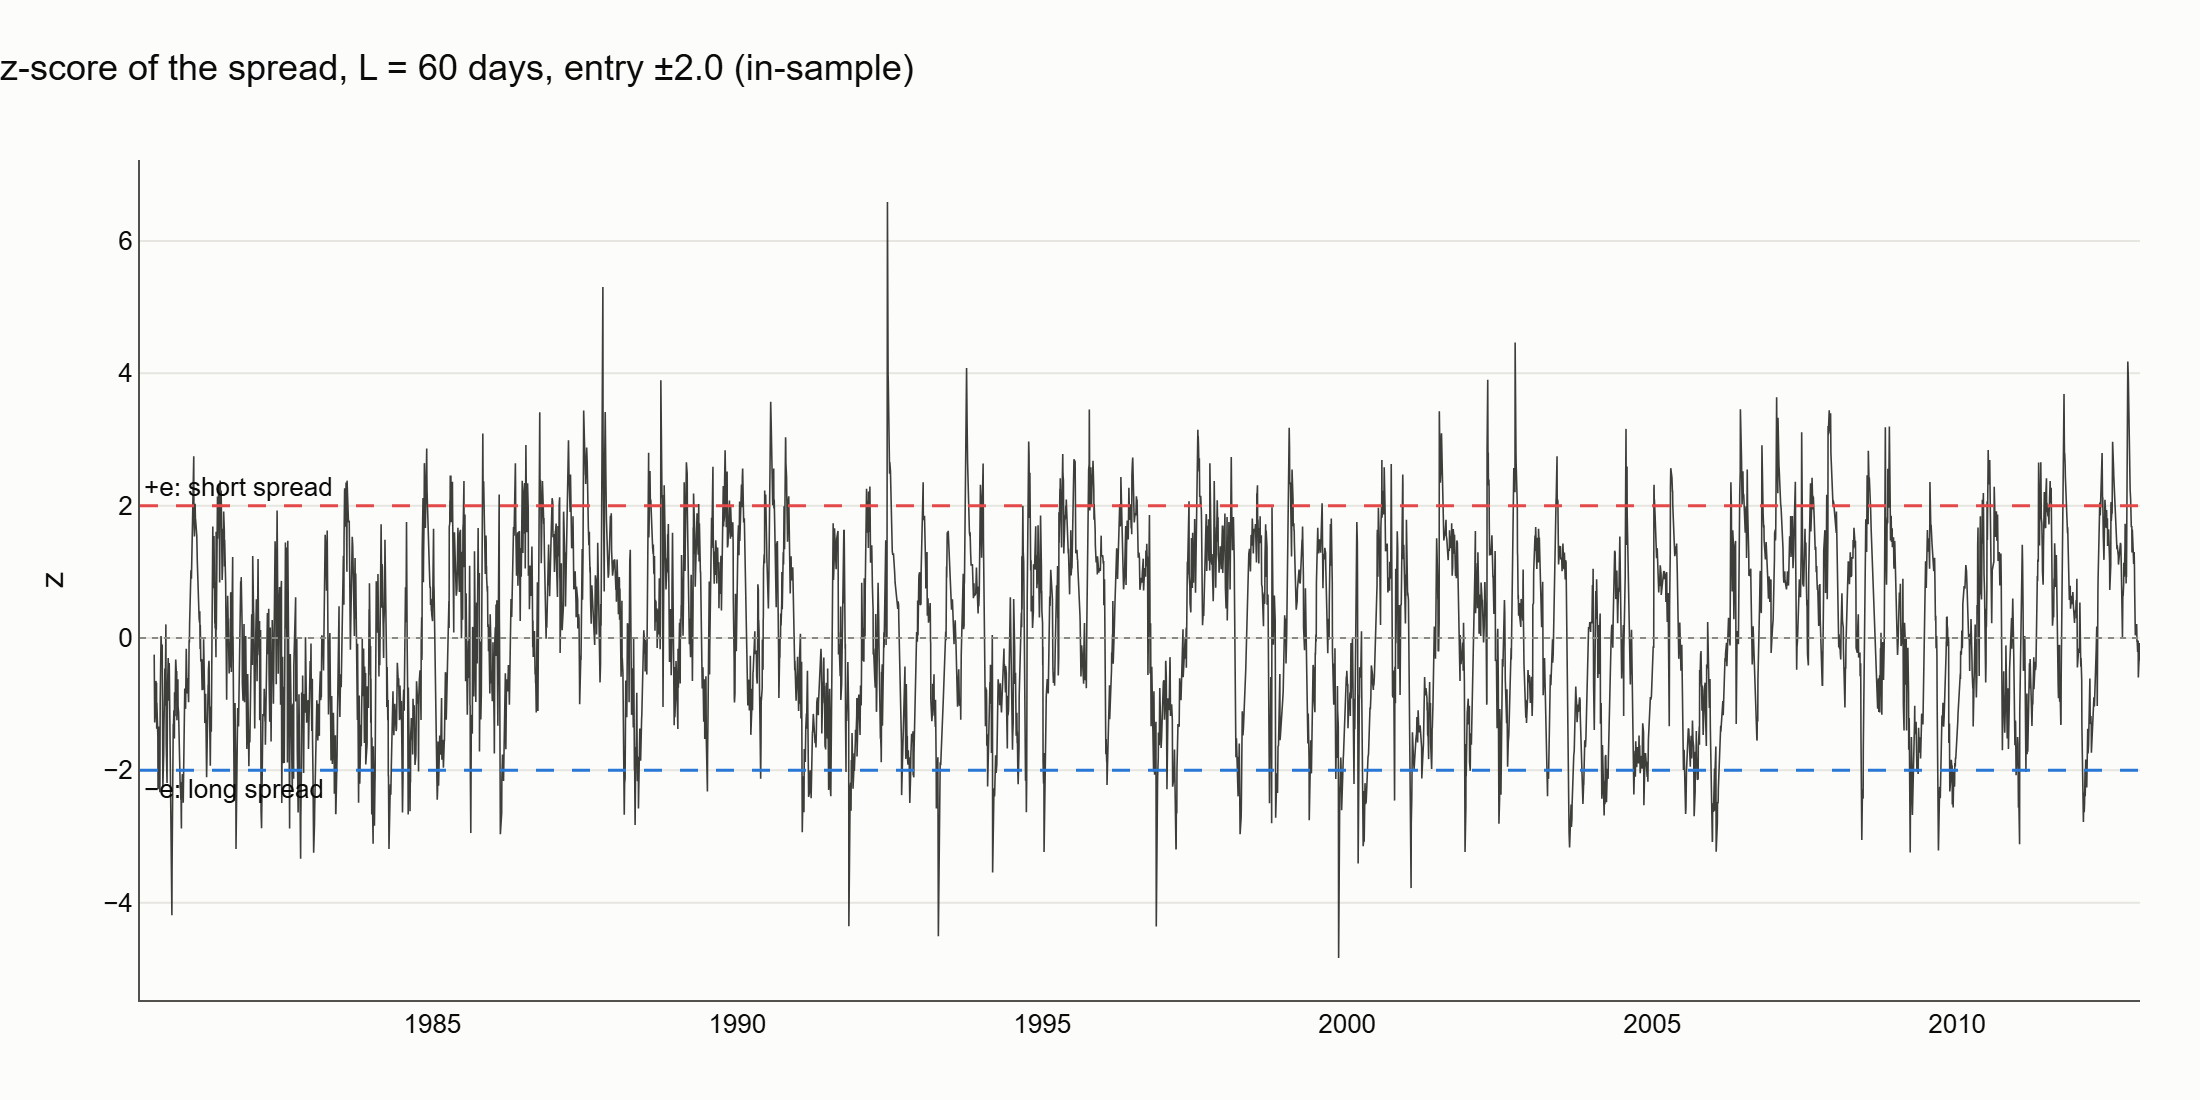

In [6]:
z_main = rolling_zscore(spread, MAIN_LOOKBACK)

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=z_main.index, y=z_main, name="z", line={"color": DERIVED_COLOR, "width": 0.8})
)
for level, label in [(MAIN_ENTRY, "+e: short spread"), (-MAIN_ENTRY, "−e: long spread")]:
    fig.add_hline(
        y=level,
        line={"color": "#e34948" if level > 0 else "#2a78d6", "width": 1.5, "dash": "dash"},
        annotation_text=label,
        annotation_position="top left" if level > 0 else "bottom left",
    )
fig.add_hline(y=0, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(
    fig, f"z-score of the spread, L = {MAIN_LOOKBACK} days, entry ±{MAIN_ENTRY} (in-sample)"
)
fig.update_layout(showlegend=False)
fig.update_yaxes(title_text="z")
_, png = save_figure(fig, "02b_zscore_main_is")
display(Image(filename=png))

The rolling z-score oscillates around zero with unit scale by construction, whatever the spread does: it subtracts a moving mean and divides by a moving standard deviation. It therefore looks mean-reverting even when the spread is a random walk, which is the trap of this signal. Spikes above 4 appear when a sudden move hits a calm 60-day window with a small standard deviation.

INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 2000-01-03..2015-05-01: alpha=-0.4638 beta=1.1222 R2=0.9043


INFO pairs.backtest: log e=2.0 L=60 lag=1: 58 trades, 2000-06-16..2015-05-01


INFO pairs.backtest: log e=2.0 L=60 lag=1: 68 trades, 2015-05-04..2030-08-30


INFO pairs.plotting: Saved figure 02h_zscore_intc_amd_vs_random_walk (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


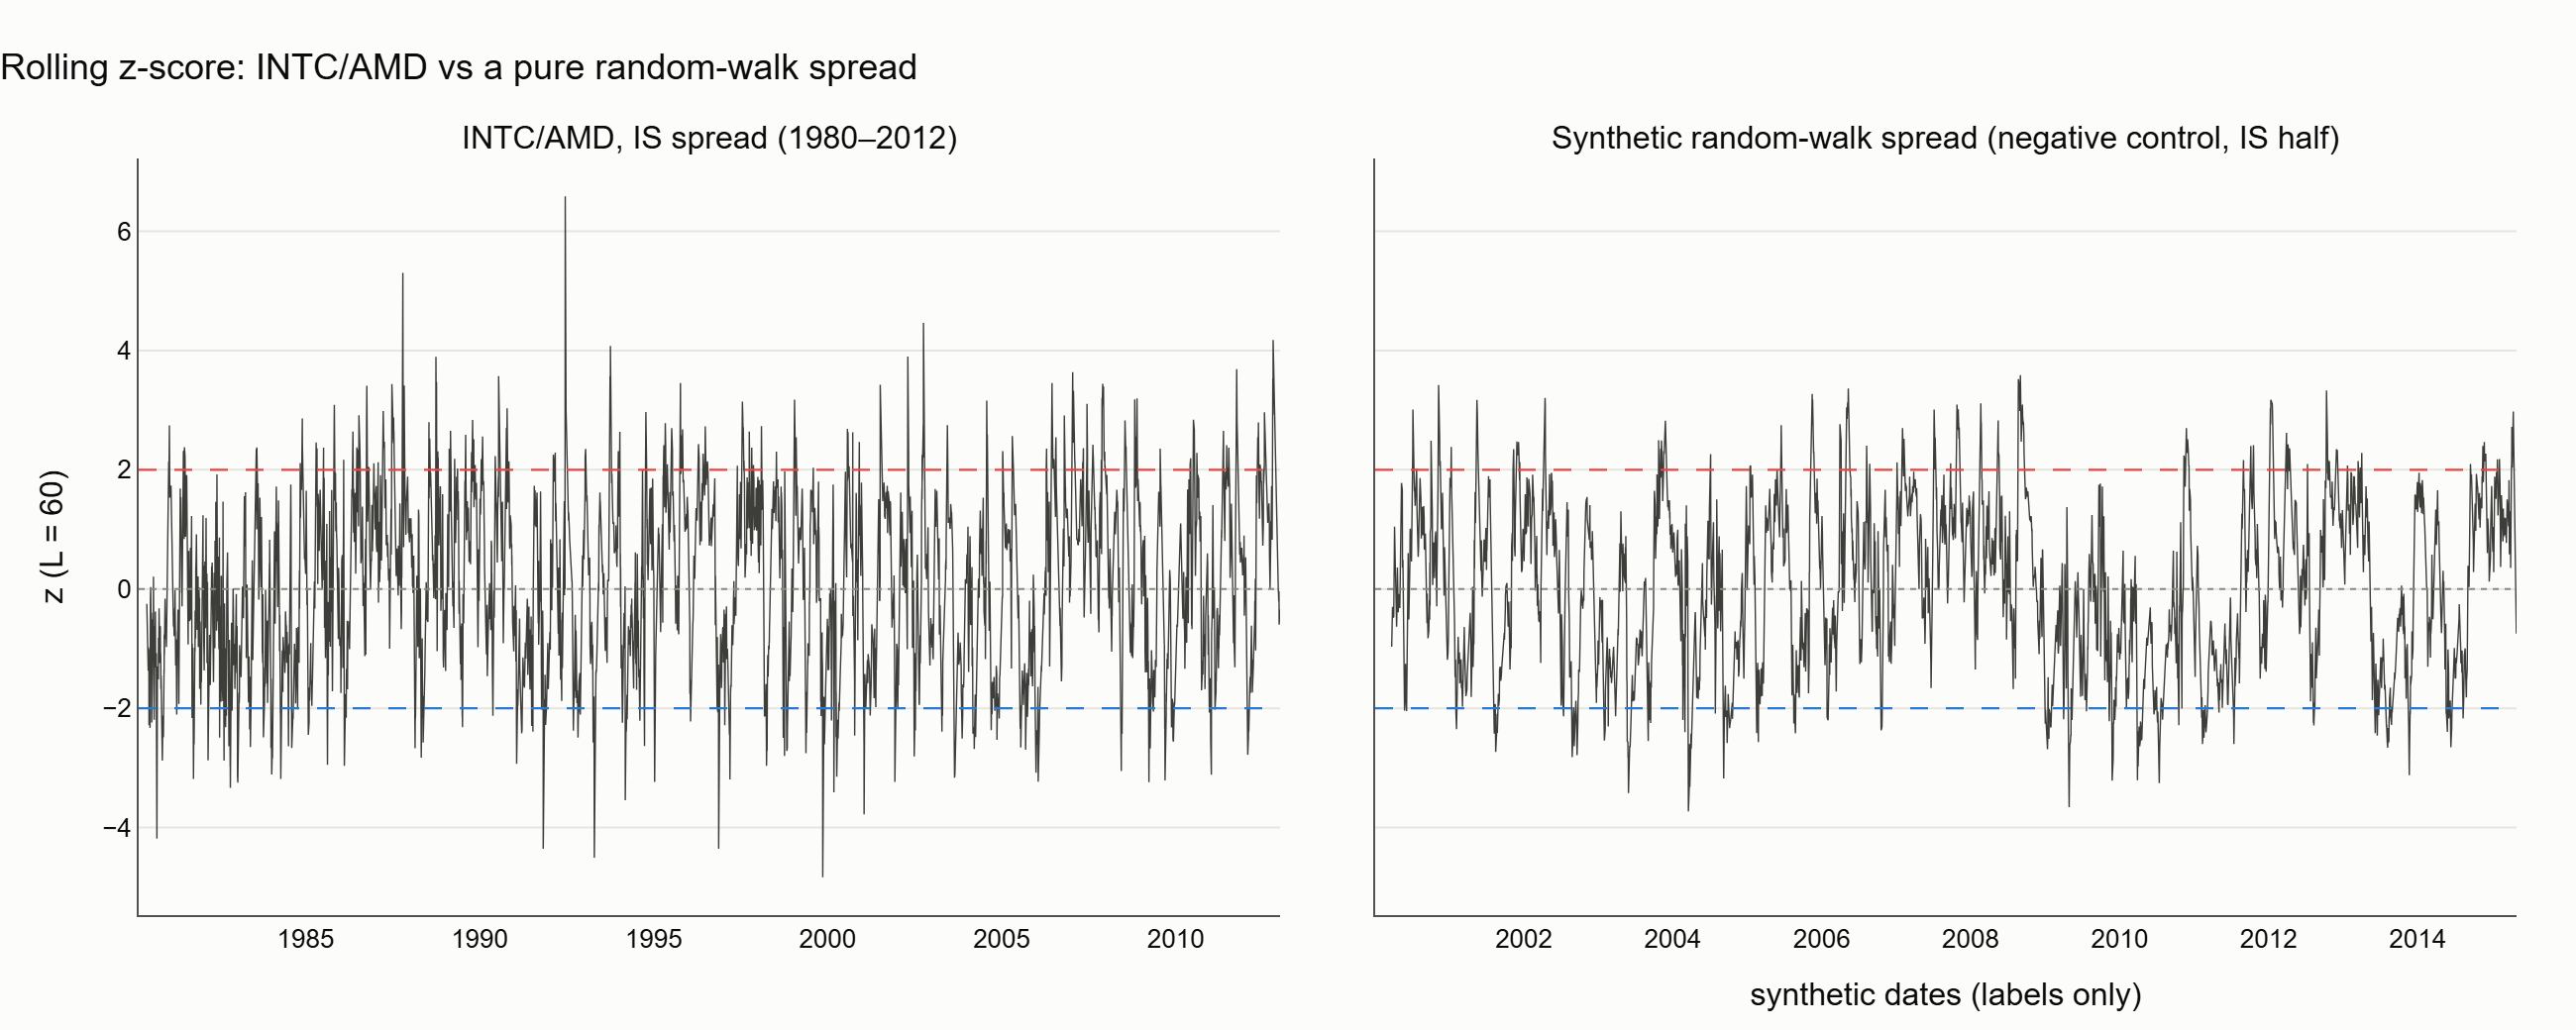

In [7]:
# Descriptive comparison: the synthetic negative control of notebook 00 (random-walk residual,
# seed 2026), spread built with the beta fitted on its first half, as in the pipeline check.
from pairs.synthetic import make_synthetic_pair, run_pipeline_control

neg = make_synthetic_pair(8000, seed=2026, mean_reverting=False)
neg_ctrl = run_pipeline_control(neg)
neg_is = neg[neg.index < pd.Timestamp(neg_ctrl.split_date)]
z_neg = rolling_zscore(compute_spread(neg_is, neg_ctrl.fit.beta), MAIN_LOOKBACK)

fig = make_subplots(
    rows=1,
    cols=2,
    shared_yaxes=True,
    horizontal_spacing=0.04,
    subplot_titles=(
        "INTC/AMD, IS spread (1980–2012)",
        "Synthetic random-walk spread (negative control, IS half)",
    ),
)
for col, z in ((1, z_main), (2, z_neg)):
    fig.add_trace(
        go.Scatter(x=z.index, y=z, line={"color": DERIVED_COLOR, "width": 0.7}), row=1, col=col
    )
    for level, color in ((MAIN_ENTRY, "#e34948"), (-MAIN_ENTRY, "#2a78d6")):
        fig.add_hline(y=level, line={"color": color, "width": 1.2, "dash": "dash"}, row=1, col=col)
    fig.add_hline(y=0, line={"color": "#8a8984", "width": 1, "dash": "dot"}, row=1, col=col)
apply_style(fig, "Rolling z-score: INTC/AMD vs a pure random-walk spread")
fig.update_layout(showlegend=False, hovermode="closest")
fig.update_yaxes(title_text=f"z (L = {MAIN_LOOKBACK})", row=1, col=1)
fig.update_xaxes(title_text="synthetic dates (labels only)", row=1, col=2)
_, png = save_figure(fig, "02h_zscore_intc_amd_vs_random_walk", width=1300, height=520)
display(Image(filename=png))

## 5. Backtest of the full pre-registered grid (9 configurations + 1 robustness run)

All configurations are evaluated on the **same window**: from the first day on which the L = 120 z-score exists to 2012-12-31; every configuration starts flat on that day.

Known optimism of an IS backtest (declared): β is estimated on the whole IS period, so a trade in 1985 uses a β that "knows" 2012.

In [8]:
trade_from = spread.index[max(LOOKBACKS) - 1].date()
print(f"Common evaluation window: {trade_from} -> {spread.index[-1].date()}")

runs = {}
for e in ENTRIES:
    for L in LOOKBACKS:
        runs[(e, L, 1)] = run_strategy(
            prices,
            fit.beta,
            entry=e,
            lookback=L,
            end=SPLIT_DATE,
            trade_from=trade_from,
            lag=1,
            cost_bps=COST_BPS,
        )
runs[(MAIN_ENTRY, MAIN_LOOKBACK, 2)] = run_strategy(
    prices,
    fit.beta,
    entry=MAIN_ENTRY,
    lookback=MAIN_LOOKBACK,
    end=SPLIT_DATE,
    trade_from=trade_from,
    lag=2,
    cost_bps=COST_BPS,
)
assert len(runs) == 10, "pre-registered number of IS backtests"
for r in runs.values():
    assert r.daily.index[0] == pd.Timestamp(trade_from)
    assert r.daily.index[-1] < pd.Timestamp(SPLIT_DATE)

summary = pd.DataFrame(
    [
        {"entry_e": e, "lookback_L": L, "lag": lag, **performance_summary(r.daily, r.trades)}
        for (e, L, lag), r in runs.items()
    ]
)

INFO pairs.backtest: log e=1.5 L=20 lag=1: 403 trades, 1980-09-04..2012-12-31


INFO pairs.backtest: log e=1.5 L=60 lag=1: 149 trades, 1980-09-04..2012-12-31


INFO pairs.backtest: log e=1.5 L=120 lag=1: 79 trades, 1980-09-04..2012-12-31


Common evaluation window: 1980-09-04 -> 2012-12-31


INFO pairs.backtest: log e=2.0 L=20 lag=1: 292 trades, 1980-09-04..2012-12-31


...

INFO pairs.backtest: log e=2.0 L=120 lag=1: 59 trades, 1980-09-04..2012-12-31


INFO pairs.backtest: log e=2.5 L=20 lag=1: 143 trades, 1980-09-04..2012-12-31


INFO pairs.backtest: log e=2.5 L=60 lag=1: 83 trades, 1980-09-04..2012-12-31


INFO pairs.backtest: log e=2.5 L=120 lag=1: 43 trades, 1980-09-04..2012-12-31


INFO pairs.backtest: log e=2.0 L=60 lag=2: 115 trades, 1980-09-04..2012-12-31


### Equity curve of the main configuration (e = 2.0, L = 60), gross and net of costs

INFO pairs.plotting: Saved figure 02c_equity_main_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


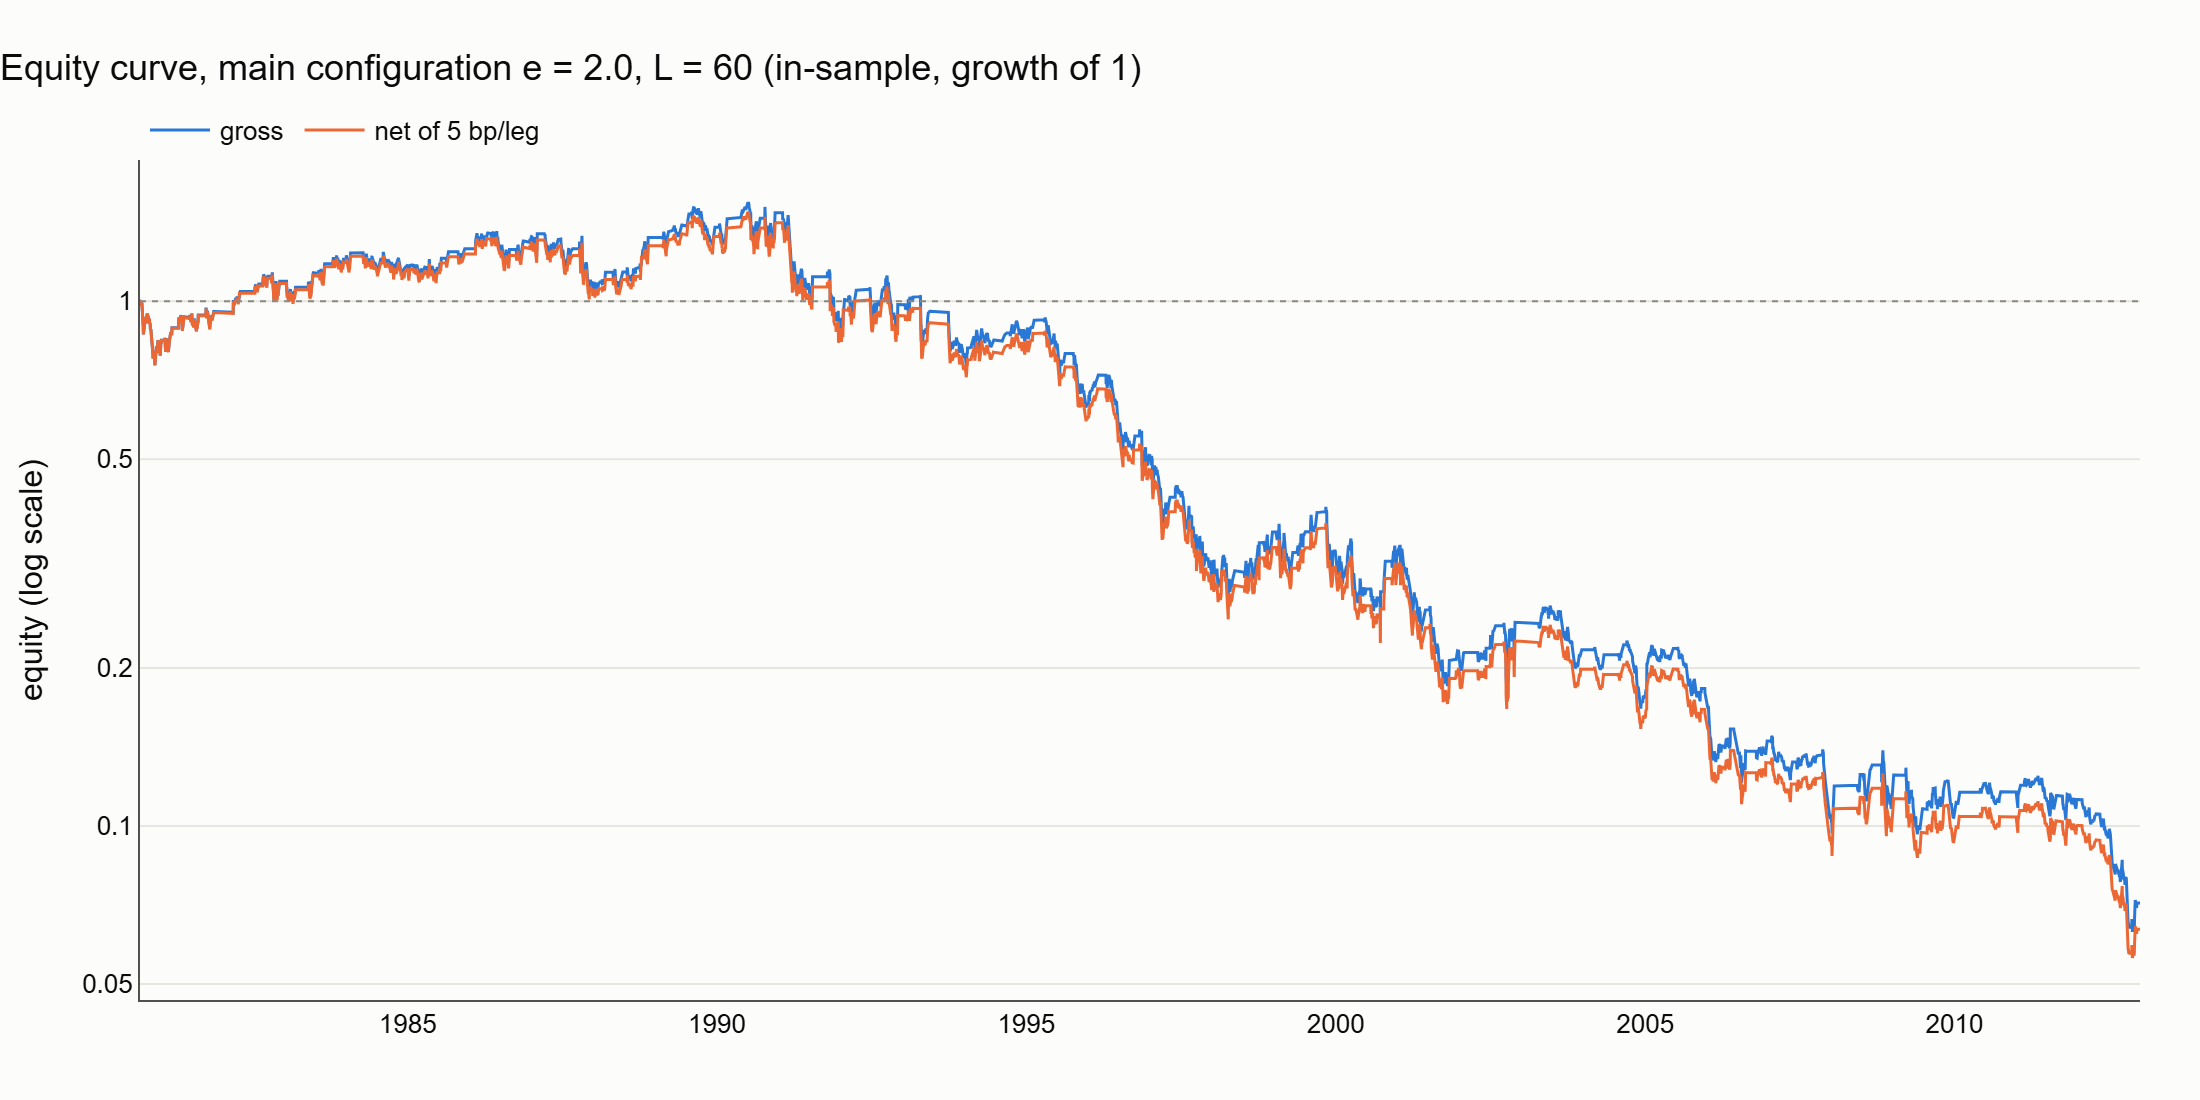

In [9]:
main = runs[(MAIN_ENTRY, MAIN_LOOKBACK, 1)].daily
eq_gross = (1 + main["gross_ret"]).cumprod()
eq_net = (1 + main["net_ret"]).cumprod()

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=eq_gross.index, y=eq_gross, name="gross", line={"color": "#2a78d6", "width": 1.5})
)
fig.add_trace(
    go.Scatter(
        x=eq_net.index, y=eq_net, name="net of 5 bp/leg", line={"color": "#eb6834", "width": 1.5}
    )
)
fig.add_hline(y=1, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "Equity curve, main configuration e = 2.0, L = 60 (in-sample, growth of 1)")
fig.update_yaxes(
    type="log",
    tickvals=[0.05, 0.1, 0.2, 0.5, 1, 2],
    title_text="equity (log scale)",
)
_, png = save_figure(fig, "02c_equity_main_is")
display(Image(filename=png))

### Sensitivity: Sharpe ratio over the whole 3×3 grid, gross and net

The grid is shown in full. It measures how much the result depends on the parameters; it is **not** used to pick a configuration (the main one was fixed a priori).

INFO pairs.plotting: Saved figure 02d_sharpe_heatmap_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


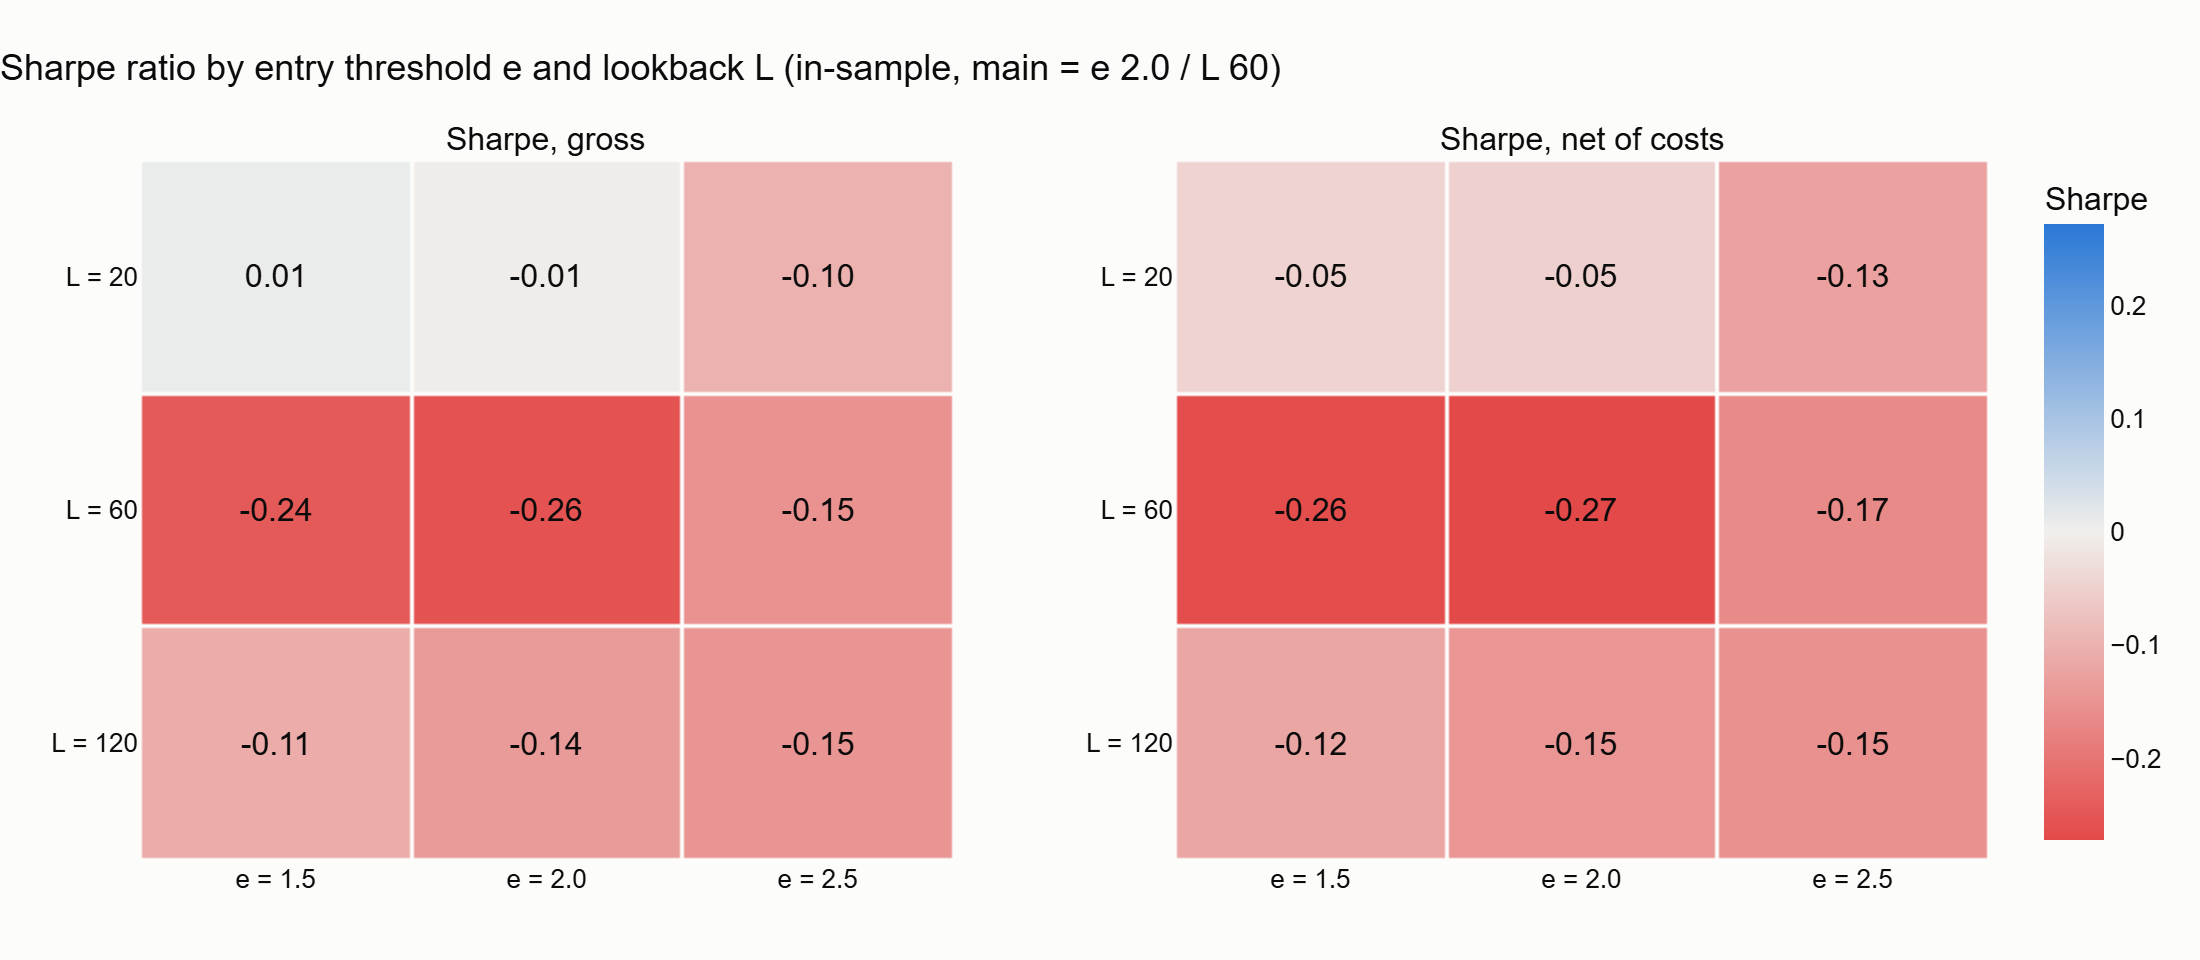

In [10]:
grid = summary[summary["lag"] == 1]
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Sharpe, gross", "Sharpe, net of costs"),
    horizontal_spacing=0.12,
)
zmax = float(np.nanmax(np.abs(grid[["sharpe_gross", "sharpe_net"]].to_numpy())))
colorscale = [[0.0, "#e34948"], [0.5, "#f0efec"], [1.0, "#2a78d6"]]
for col, kind in enumerate(["gross", "net"], start=1):
    mat = grid.pivot(index="lookback_L", columns="entry_e", values=f"sharpe_{kind}")
    fig.add_trace(
        go.Heatmap(
            z=mat.to_numpy(),
            x=[f"e = {e}" for e in mat.columns],
            y=[f"L = {L}" for L in mat.index],
            colorscale=colorscale,
            zmin=-zmax,
            zmid=0,
            zmax=zmax,
            text=np.vectorize(lambda v: f"{v:.2f}")(mat.to_numpy()),
            texttemplate="%{text}",
            textfont={"size": 16, "color": "#0b0b0b"},
            showscale=(col == 2),
            colorbar={"title": "Sharpe"},
            xgap=2,
            ygap=2,
        ),
        row=1,
        col=col,
    )
apply_style(
    fig, "Sharpe ratio by entry threshold e and lookback L (in-sample, main = e 2.0 / L 60)"
)
fig.update_xaxes(showline=False)
fig.update_yaxes(showline=False, gridcolor="rgba(0,0,0,0)", autorange="reversed")
fig.update_layout(hovermode="closest")
_, png = save_figure(fig, "02d_sharpe_heatmap_is", height=480)
display(Image(filename=png))

### All metrics, all 10 IS backtests

Returns, volatility and drawdowns in %, durations in trading days. `win_rate_net` = share of trades with positive net return. `lag = 2` is the pre-registered robustness run (one extra day of execution delay).

In [11]:
table = summary.copy()
pct_cols = [c for c in table.columns if c.startswith(("ann_return", "ann_vol", "max_dd"))] + [
    "win_rate_net",
    "exposure",
]
table[pct_cols] = table[pct_cols] * 100
table = table.rename(columns={c: f"{c} %" for c in pct_cols})
table = table.astype({"n_trades": int, "n_open_at_end": int})
table.round(2)

,entry_e,lookback_L,lag,ann_return_gross %,ann_vol_gross %,sharpe_gross,max_dd_gross %,ann_return_net %,ann_vol_net %,sharpe_net,max_dd_net %,n_trades,win_rate_net %,avg_duration_days,max_duration_days,exposure %,n_open_at_end
0,1.5,20,1,-2.42,22.93,0.01,-92.15,-3.63,22.93,-0.05,-93.80,403,64.27,13.90,92.0,68.69,0
1,1.5,60,1,-8.13,23.46,-0.24,-96.97,-8.55,23.46,-0.26,-97.25,149,58.39,39.52,193.0,72.21,0
2,1.5,120,1,-5.12,23.27,-0.11,-93.53,-5.35,23.27,-0.12,-93.86,79,68.35,75.77,494.0,73.41,1
3,2.0,20,1,-2.25,20.78,-0.01,-92.95,-3.13,20.78,-0.05,-94.04,292,62.33,15.07,91.0,53.96,0
4,2.0,60,1,-7.84,22.22,-0.26,-95.93,-8.16,22.22,-0.27,-96.21,115,53.91,45.35,188.0,63.96,0
5,2.0,120,1,-5.30,21.99,-0.14,-87.99,-5.47,21.99,-0.15,-88.53,59,61.02,87.97,487.0,63.65,1
6,2.5,20,1,-2.91,16.24,-0.10,-86.36,-3.34,16.24,-0.13,-87.57,143,59.44,16.84,89.0,29.53,0
7,2.5,60,1,-4.87,19.83,-0.15,-90.09,-5.12,19.84,-0.17,-90.61,83,57.83,47.39,155.0,48.23,0
8,2.5,120,1,-4.94,20.34,-0.15,-84.50,-5.07,20.33,-0.15,-85.02,43,53.49,101.44,479.0,53.50,1
9,2.0,60,2,-8.43,22.14,-0.29,-95.38,-8.75,22.14,-0.30,-95.72,115,55.65,45.35,188.0,63.96,0


### Diagnostic: why does the main configuration lose with a win rate above 50%?

Same trades as the main backtest above (no new backtest). Split by direction, and the largest wins and losses.

In [12]:
trades = runs[(MAIN_ENTRY, MAIN_LOOKBACK, 1)].trades.copy()
trades["side"] = trades["direction"].map({1: "long spread", -1: "short spread"})
trades["log_net"] = np.log1p(trades["net_return"])

by_side = trades.groupby("side").agg(
    n_trades=("net_return", "size"),
    win_rate_pct=("net_return", lambda r: 100 * (r > 0).mean()),
    avg_win_pct=("net_return", lambda r: 100 * r[r > 0].mean()),
    avg_loss_pct=("net_return", lambda r: 100 * r[r <= 0].mean()),
    total_log_return=("log_net", "sum"),
)
by_side.loc["all"] = [
    len(trades),
    100 * (trades["net_return"] > 0).mean(),
    100 * trades.loc[trades["net_return"] > 0, "net_return"].mean(),
    100 * trades.loc[trades["net_return"] <= 0, "net_return"].mean(),
    trades["log_net"].sum(),
]
display(by_side.round(2))

cols = ["entry_date", "exit_date", "side", "duration_days", "net_return"]
worst = trades.nsmallest(5, "net_return")[cols]
best = trades.nlargest(5, "net_return")[cols]
display(pd.concat({"worst 5": worst, "best 5": best}).round(3))

,n_trades,win_rate_pct,avg_win_pct,avg_loss_pct,total_log_return
side,,,,,
long spread,56.0,55.36,4.93,-10.28,-1.34
short spread,59.0,52.54,4.17,-8.70,-1.41
all,115.0,53.91,4.55,-9.45,-2.76


C:\Users\cloti\AppData\Local\Temp\ipykernel_9376\109742619.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(pd.concat({"worst 5": worst, "best 5": best}).round(3))


entry_date  exit_date          side  duration_days  net_return
worst 5 114 2012-05-07 2012-12-13  short spread            153      -0.324
        44  1991-01-24 1991-07-19   long spread            123      -0.245
        77  2001-01-18 2001-06-06   long spread             97      -0.244
        62  1996-10-30 1997-04-21   long spread            119      -0.237
        61  1996-04-10 1996-09-25  short spread            118      -0.236
best 5  75  2000-10-12 2000-10-17   long spread              4       0.142
        72  2000-03-08 2000-03-27   long spread             14       0.104
        81  2002-07-01 2002-07-26   long spread             19       0.103
        69  1999-05-20 1999-06-28   long spread             27       0.094
        104 2009-07-23 2009-08-28  short spread             27       0.092

## Observations (in-sample only; no parameter changed after seeing these results)

- **Hedge regression.** β = 1.047 > 0, so AMD does act as a hedge in the regression; but R² = 0.15: log AMD explains only 15% of the variance of log INTC over 1980–2012.
- **The IS spread is not stationary.** ADF p = 0.92, Engle–Granger p = 0.975: no evidence at all of cointegration. The AR(1) coefficient is ≈ −0.0001, i.e. a half-life of ≈ 6,700 trading days (≈ 27 years) — longer than any trade and comparable to the whole sample. The spread chart shows the same thing: long trends (1985–2000 up, 2000–2006 down, 2006–2012 up) rather than oscillations around the mean of −1.23.
- **The main configuration (e = 2.0, L = 60) loses in-sample:** Sharpe −0.26 gross / −0.27 net, −7.8% / −8.2% a year, max drawdown −96%. It made money only until about 1990, then lost steadily for two decades.
- **Why it loses with a 54% win rate:** the average losing trade (−9.5%) is about twice the average winning trade (+4.6%). Winners are short (the spread snaps back quickly); losers are long trades in which the spread keeps drifting away for 100–150 days, and without a stop-loss nothing cuts them. Long-spread and short-spread trades lose about equally, so it is not a single directional bet but a spread with no stable mean.
- **The rolling z-score hides this.** By construction z is re-centred every L days, so it *looks* mean-reverting (chart 4) even though the spread is not: the z-score keeps signalling "extreme, it will revert" while the level it should revert to keeps moving.
- **Sensitivity.** All 9 configurations have negative net Sharpe (−0.05 to −0.27); gross Sharpe ranges from +0.01 to −0.26. The result is not a fragile accident of one parameter choice: the whole grid fails. The L = 20 row is closest to zero (gross 0.01 / −0.01 / −0.10), but it is still ≤ 0 net and is **not** a reason to switch configuration (pre-registered).
- **Robustness (lag 2).** One extra day of execution delay makes the main configuration slightly worse (Sharpe net −0.30 vs −0.27).
- **Costs** are not the problem: 5 bp/leg lowers the Sharpe by at most 0.06; the strategy already loses gross.

## Robustness: price levels as in the brief

Pre-registered in `EXPERIMENTS.md` (2026-10-10 12:36 CEST) before computing it; counted as IS backtest #11.

Phase 2 deviated from the brief by regressing **log** prices. This run uses the brief's literal version, to check that the negative result does not depend on that choice. It is not a new candidate strategy.

- OLS on IS: `P_INTC = α + β·P_AMD + ε` (adjusted prices, USD); spread `P_INTC − β·P_AMD`.
- Main configuration only: e = 2.0, L = 60, `shift(1)`, same rules, costs, metrics and evaluation window.
- P&L: hold 1 share of INTC and β shares of AMD; daily return `position × (ΔP_INTC − β·ΔP_AMD) / (P_INTC,t−1 + |β|·P_AMD,t−1)`.

Meaning of the coefficients here: **β** = how many dollars INTC moves on average per 1 USD move of AMD, i.e. shares of AMD per share of INTC in the hedge; **α** = intercept in USD (a level shift, removed by the z-score); **R²** = share of the variance of the INTC *price* explained by the AMD price.

In [13]:
fit_lv = fit_hedge_ratio(prices, end=SPLIT_DATE, use_logs=False)
if fit_lv.beta <= 0:
    print(f"PROBLEM: beta = {fit_lv.beta:.4f} <= 0, the AMD leg is not a hedge.")
elif fit_lv.beta <= BETA_WARNING_THRESHOLD:
    print(f"PROBLEM: beta = {fit_lv.beta:.4f} is close to zero, the AMD leg barely hedges INTC.")
else:
    print(f"beta = {fit_lv.beta:.4f} > {BETA_WARNING_THRESHOLD}: AMD acts as a hedge for INTC.")

st_lv = stationarity_tests(prices, beta=fit_lv.beta, end=SPLIT_DATE, use_logs=False)
display(
    pd.DataFrame(
        {
            "log prices (main)": [fit.alpha, fit.beta, fit.r_squared],
            "price levels": [fit_lv.alpha, fit_lv.beta, fit_lv.r_squared],
        },
        index=["alpha", "beta", "R²"],
    ).round(4)
)
display(
    pd.DataFrame(
        {
            "statistic": [st_lv.adf_stat, st_lv.eg_stat],
            "p_value": [st_lv.adf_pvalue, st_lv.eg_pvalue],
        },
        index=[f"ADF on price spread (lags={st_lv.adf_lags})", "Engle–Granger (prices)"],
    ).round(4)
)
print(
    f"Descriptive only: AR(1) b = {st_lv.ar1_coef:.5f}, implied half-life ≈ "
    f"{st_lv.half_life_days:,.0f} trading days."
)

INFO pairs.spread: Hedge fit (price levels) INTC ~ AMD on 1980-03-17..2012-12-31: alpha=2.1677 beta=0.5255 R2=0.2213


beta = 0.5255 > 0.1: AMD acts as a hedge for INTC.


,log prices (main),price levels
alpha,-1.2311,2.1677
beta,1.0471,0.5255
R²,0.1499,0.2213


,statistic,p_value
ADF on price spread (lags=36),-1.6193,0.4731
Engle–Granger (prices),-1.6211,0.7119


Descriptive only: AR(1) b = -0.00092, implied half-life ≈ 751 trading days.


INFO pairs.plotting: Saved figure 02e_spread_levels_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


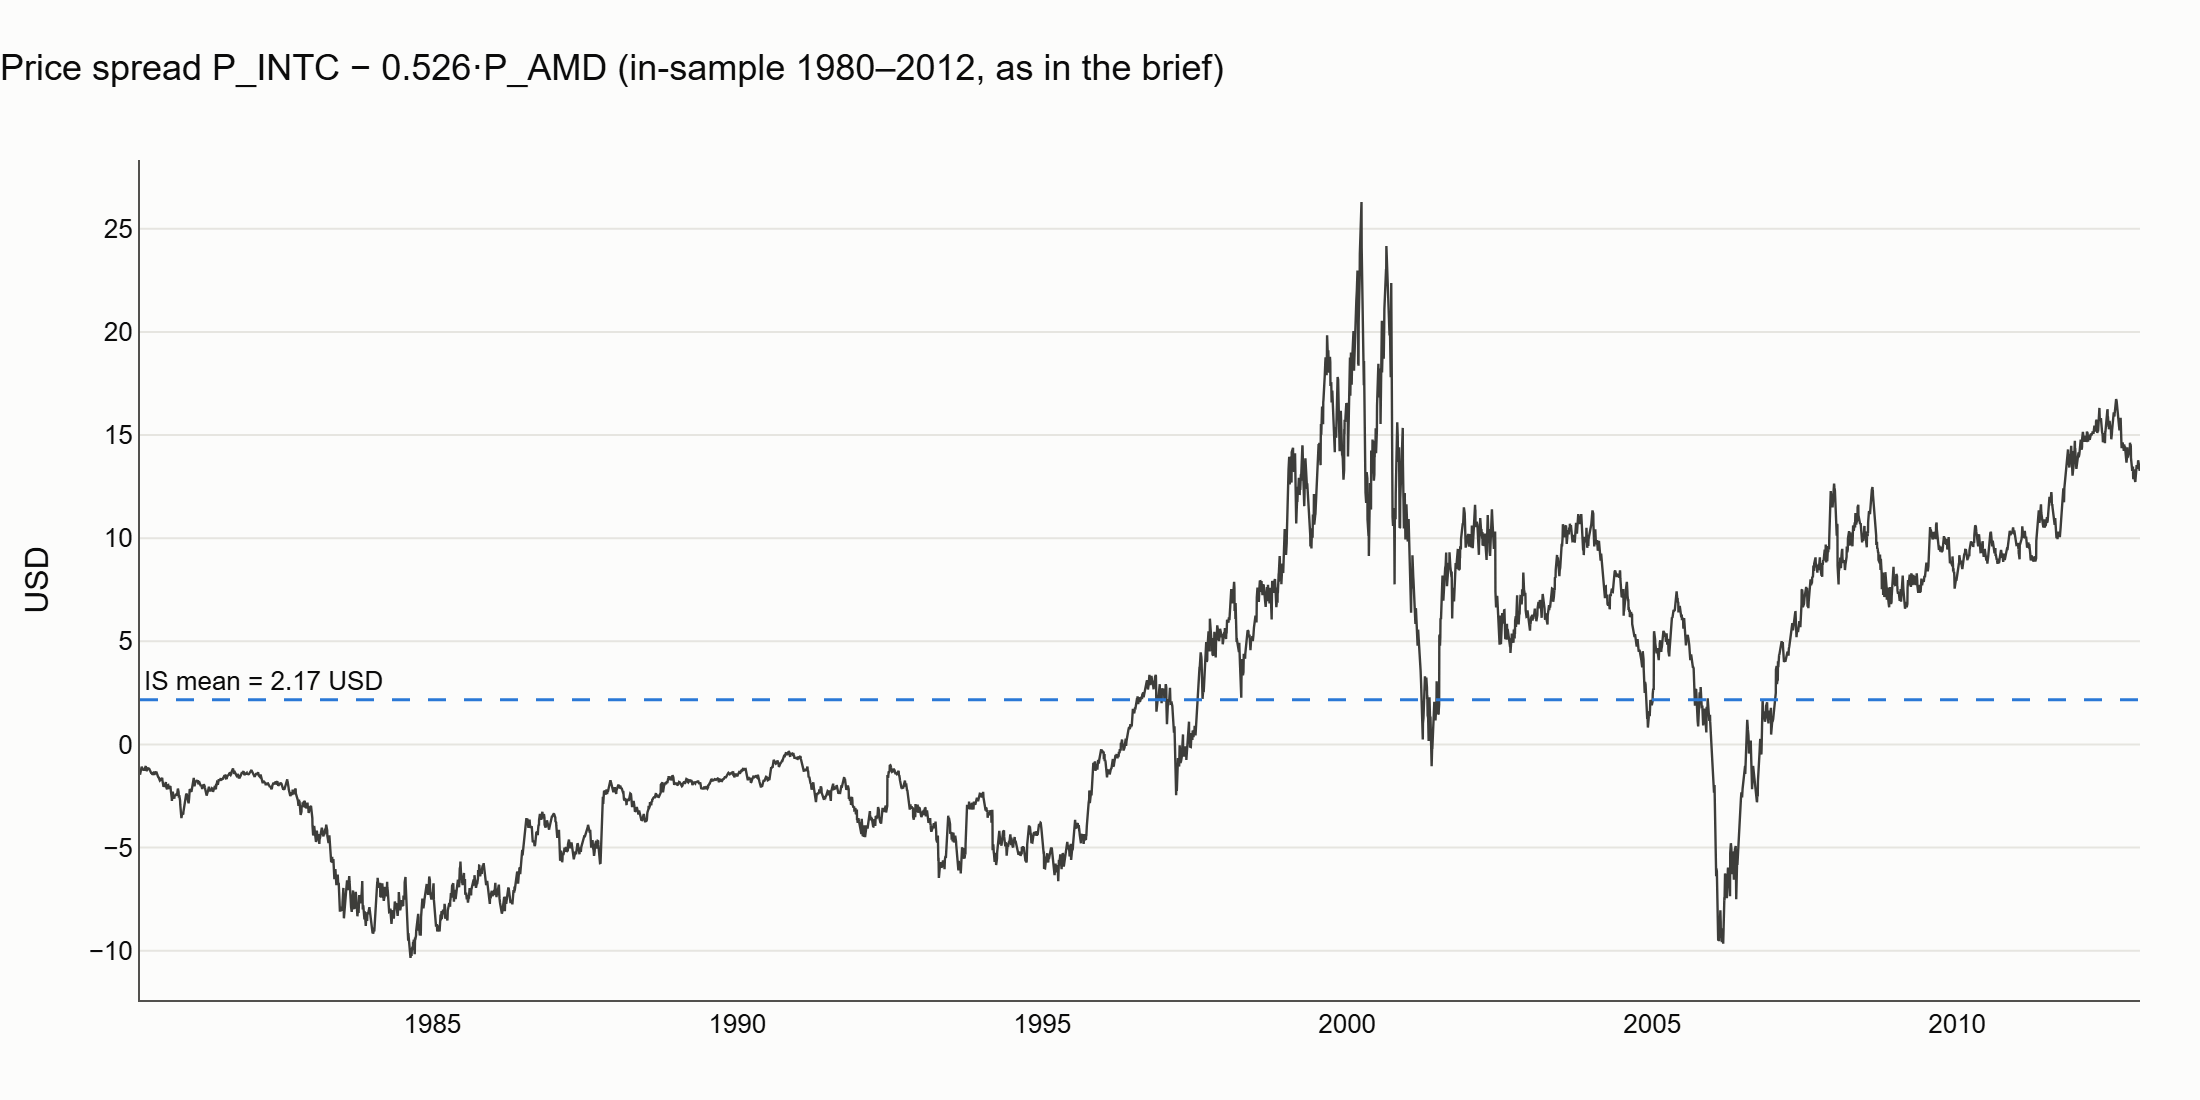

In [14]:
spread_lv = compute_spread(prices, fit_lv.beta, use_logs=False)
assert abs(spread_lv.mean() - fit_lv.alpha) < 1e-8

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=spread_lv.index, y=spread_lv, name="spread", line={"color": DERIVED_COLOR, "width": 1.2}
    )
)
fig.add_hline(
    y=spread_lv.mean(),
    line={"color": "#2a78d6", "width": 1.5, "dash": "dash"},
    annotation_text=f"IS mean = {spread_lv.mean():.2f} USD",
    annotation_position="top left",
)
apply_style(
    fig, f"Price spread P_INTC − {fit_lv.beta:.3f}·P_AMD (in-sample 1980–2012, as in the brief)"
)
fig.update_layout(showlegend=False)
fig.update_yaxes(title_text="USD")
_, png = save_figure(fig, "02e_spread_levels_is")
display(Image(filename=png))

In [15]:
run_lv = run_strategy(
    prices,
    fit_lv.beta,
    entry=MAIN_ENTRY,
    lookback=MAIN_LOOKBACK,
    end=SPLIT_DATE,
    trade_from=trade_from,
    lag=1,
    cost_bps=COST_BPS,
    use_logs=False,
)
assert run_lv.daily.index[0] == pd.Timestamp(trade_from)
assert run_lv.daily.index.equals(runs[(MAIN_ENTRY, MAIN_LOOKBACK, 1)].daily.index)

main_run = runs[(MAIN_ENTRY, MAIN_LOOKBACK, 1)]
compare = pd.DataFrame(
    {
        "log prices (main)": performance_summary(main_run.daily, main_run.trades),
        "price levels (brief)": performance_summary(run_lv.daily, run_lv.trades),
    }
)
pct_rows = [r for r in compare.index if r.startswith(("ann_return", "ann_vol", "max_dd"))] + [
    "win_rate_net",
    "exposure",
]
compare.loc[pct_rows] = compare.loc[pct_rows] * 100
compare = compare.rename(index={r: f"{r} %" for r in pct_rows})
compare.round(2)

INFO pairs.backtest: levels e=2.0 L=60 lag=1: 116 trades, 1980-09-04..2012-12-31


,log prices (main),price levels (brief)
ann_return_gross %,-7.84,-8.37
ann_vol_gross %,22.22,28.22
sharpe_gross,-0.26,-0.17
max_dd_gross %,-95.93,-97.21
ann_return_net %,-8.16,-8.69
ann_vol_net %,22.22,28.21
sharpe_net,-0.27,-0.18
max_dd_net %,-96.21,-97.45
n_trades,115.00,116.00
win_rate_net %,53.91,56.03


### Diagnostic: how the price-level hedge is weighted over time

With a fixed number of shares (1 INTC, β AMD), the share of gross capital in the AMD leg changes with the two price levels. Median by decade (descriptive, no new backtest).

In [16]:
amd_leg = fit_lv.beta * prices[TICKER_B] / (prices[TICKER_A] + fit_lv.beta * prices[TICKER_B])
by_decade = amd_leg.groupby((amd_leg.index.year // 10) * 10).median().mul(100).round(1)
by_decade.index = [f"{d}s" for d in by_decade.index]
by_decade.rename("AMD leg, % of gross capital (median)").to_frame()

,"AMD leg, % of gross capital (median)"
1980s,92.3
1990s,69.0
2000s,31.2
2010s,20.4


### Observations on the price-level robustness run

- **Regression:** α = 2.17 USD, β = 0.526 (> 0, AMD acts as a hedge), R² = 0.22.
- **Not stationary either:** ADF p = 0.47, Engle–Granger p = 0.71. The price spread stays below its IS mean from 1980 to about 1996 and above it for most of 1997–2012.
- **Main configuration on price levels loses too:** Sharpe −0.17 gross / −0.18 net (vs −0.26 / −0.27 in logs), −8.4% / −8.7% a year, max drawdown −97%, 116 trades, win rate 56%.
- **Why the volatility is higher (28% vs 22%):** with a fixed number of shares the book is not balanced over time — the AMD leg is a median 92% of gross capital in the 1980s and 20% in the 2010s. In the early years the "pair" is mostly an AMD position, later mostly an INTC position. This is the scaling problem that motivated the log-price design.
- **Conclusion of the check:** the negative Phase 2 result does not depend on the choice of log prices. With the brief's literal version the spread is still non-stationary and the main configuration still loses, both gross and net.